In [22]:
import pandas as pd
import numpy as np
import sys
from pathlib import Path

project_dir = Path.cwd()
if not (project_dir / "plot_style.py").exists():
    project_dir = project_dir.parent
sys.path.insert(0, str(project_dir))
from plot_style import *

In [23]:
scal = pd.read_csv("./TESTING_DNUTYPE_scal.csv")
asf = pd.read_csv("./TESTING_DNUTYPE_asf.csv")

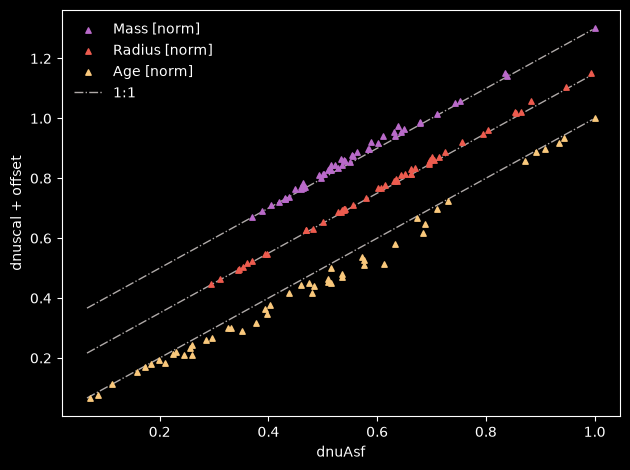

In [24]:
mass_scal = scal["massfin"] 
mass_asf = asf["massfin"] 
rad_scal = scal["radPhot"] 
rad_asf = asf["radPhot"] 
age_scal = scal["age"] 
age_asf = asf["age"] 

mass_max = np.max(np.append(mass_scal, mass_asf))
rad_max = np.max(np.append(rad_scal, rad_asf))
age_max = np.max(np.append(age_scal, age_asf))
full_min = min(np.min(rad_scal / rad_max), np.min(rad_asf / rad_max),
               np.min(mass_scal / mass_max), np.min(mass_asf / mass_max),
               np.min(age_scal / age_max), np.min(age_asf / age_max))

# plt.scatter(x_scal, y_scal, c="blue", label=f"{fit_scal[1]:4f}, {fit_scal[0]:4f}")
# plt.scatter(x_asf, y_asf, c="red", label=f"{fit_asf[1]:4f}, {fit_asf[0]:4f}")
plt.scatter(mass_asf / mass_max, mass_scal / mass_max + 0.3, color=c6, zorder=2,
            marker="^", s=15, label="Mass [norm]")
plt.scatter(rad_asf / rad_max, rad_scal / rad_max + 0.15, color=c3, zorder=2,
            marker="^", s=15, label="Radius [norm]")
plt.scatter(age_asf / age_max, age_scal / age_max, color=c1, zorder=2,
            marker="^", s=15, label="Age [norm]")
plt.plot(np.arange(full_min, 1, 0.01), np.arange(full_min, 1, 0.01), ms=0, ls="-.", 
         lw=1, alpha=0.7, c=light, zorder=1, label="1:1")
plt.plot(np.arange(full_min, 1, 0.01), np.arange(full_min, 1, 0.01) + 0.15, ms=0, ls="-.", 
         lw=1, alpha=0.7, c=light, zorder=1)
plt.plot(np.arange(full_min, 1, 0.01), np.arange(full_min, 1, 0.01) + 0.3, ms=0, ls="-.", 
         lw=1, alpha=0.7, c=light, zorder=1)
plt.legend()
plt.xlabel("dnuAsf")
plt.ylabel("dnuscal + offset")
plt.tight_layout()
plt.savefig("./figures/TESTING_DNUTYPE_scalvAsf.png", dpi=200)
plt.show()